<div style="
background:linear-gradient(135deg,#171922,#10131b);
border:2px solid #3ce7e7;
border-radius:22px;
padding:32px;
font-family:-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Arial,sans-serif;
color:white;
box-shadow:0 0 18px rgba(60,231,231,.18);
">

<div style="display:flex;align-items:center;gap:14px;">
<span style="font-size:34px;">👨‍💻</span>

<div>
<div style="
font-size:34px;
font-weight:800;
color:#4ff5f5;
text-shadow:0 0 8px rgba(79,245,245,.35);
">
Aliakbar Isapour
</div>

<div style="
color:#bfbfbf;
font-size:16px;
margin-top:3px;
">
Machine Learning • Data Science • AI
</div>
</div>
</div>

<div style="
height:2px;
background:linear-gradient(90deg,#7b3ff2,#4ff5f5);
border-radius:5px;
margin:22px 0;
"></div>

<div style="
color:#d7d7d7;
font-size:16px;
line-height:1.7;
margin-bottom:25px;
">

</div>


<div style="display:flex;gap:14px;flex-wrap:wrap;">

<a href="https://github.com/isapour0"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
GitHub
</a>

<a href="https://www.linkedin.com/in/aliakbar-isapour-682592413"
target="_blank"
rel="noopener noreferrer"
style="
display:inline-block;
margin: 0 10px;
text-decoration:none;
background:#23283a;
color:#4ff5f5;
padding:12px 22px;
border-radius:12px;
border:1px solid #4ff5f5;
font-weight:bold;
transition:0.25s;
">
LinkedIn
</a>


</div>

</div>

<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">📌 Library Imports</h2>
<hr style="border:1px solid #8A2BE2; opacity:.4;">
</div>


In [1]:
# ---- core ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
import warnings
import time

# ---- modelSelection and metrics ----
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report

# ---- keras ----
from tensorflow.keras.datasets import cifar10
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau 
from tensorflow.keras.utils import to_categorical

RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

classes_name = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

I0000 00:00:1795803904.051208   28843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795803904.149269   28843 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795803906.226511   28843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-radius:18px;
border-left: 8px solid #00E5FF;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">
    
<h2 style="color:#00E5FF;">📂 Data Loading</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">
</div>


In [2]:
DATA_DIR = Path("../data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

paths = {name: DATA_DIR / f"{name}.npy" for name in ["X_train", "y_train", "X_test", "y_test"]}

if all(p.exists() for p in paths.values()):
    print("Loading CIFAR-10 from local .npy files...")
    X_train = np.load(paths["X_train"])
    y_train = np.load(paths["y_train"])
    X_test = np.load(paths["X_test"])
    y_test = np.load(paths["y_test"])
else:
    print("Downloading CIFAR-10 with Keras...")
    (X_train, y_train), (X_test, y_test) = cifar10.load_data()
    np.save(paths["X_train"], X_train)
    np.save(paths["y_train"], y_train)
    np.save(paths["X_test"], X_test)
    np.save(paths["y_test"], y_test)
    print("Saved to", DATA_DIR.resolve())

Loading CIFAR-10 from local .npy files...


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🔧 Preprocessing</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<ul>
    
<li>Step 1: Separating a 10% validation set.</li> 
<li>Step 2: Scaling pixels to the range [0, 1].</li>
<li>One-hot encoding of the labels (the integer labels stay available for evaluation)</li> 

</ul>
</div>

In [3]:
# Step 1: Separating a 15% validation set
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train, y_train,
    test_size=0.10,
    stratify=y_train.ravel(),
    random_state=RANDOM_STATE,
)

print("Train part:", X_train_part.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)

Train part: (45000, 32, 32, 3) | Validation: (5000, 32, 32, 3) | Test: (10000, 32, 32, 3)


In [4]:
# Step 2: Scaling pixels to the range [0, 1]
def prepare_images(X):
    """uint8 images (N, 32, 32, 3) -> float32 in [0, 1], same shape."""
    if X.dtype != np.uint8:
        raise ValueError(f"Expected uint8 images, got {X.dtype}. Was this data already scaled?")
    return X.astype("float32") / 255.0

X_train_scaled = prepare_images(X_train_part)
X_val_scaled = prepare_images(X_val)
X_test_scaled = prepare_images(X_test)

for name, arr in [("X_train_scaled", X_train_scaled), ("X_val_scaled", X_val_scaled), ("X_test_scaled", X_test_scaled)]:
    print(f"{name:15s} shape={arr.shape}  dtype={arr.dtype}  min={arr.min():.1f}  max={arr.max():.1f}")

X_train_scaled  shape=(45000, 32, 32, 3)  dtype=float32  min=0.0  max=1.0
X_val_scaled    shape=(5000, 32, 32, 3)  dtype=float32  min=0.0  max=1.0
X_test_scaled   shape=(10000, 32, 32, 3)  dtype=float32  min=0.0  max=1.0


In [5]:
# Step 3: One-hot encoding of the labels (the integer labels stay available for evaluation)
y_train_cat = to_categorical(y_train_part, num_classes=10)
y_val_cat = to_categorical(y_val, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

print("y_train_cat:", y_train_cat.shape, "| y_val_cat:", y_val_cat.shape, "| y_test_cat:", y_test_cat.shape)

y_train_cat: (45000, 10) | y_val_cat: (5000, 10) | y_test_cat: (10000, 10)


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🤖 Baseline CNN Model</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

<li>Step 1: Architecture: 3 x [Conv2D (3x3, ReLU, same padding) + MaxPooling [2x2] with 32, 64 and 128 filters, then Flatten, Dense(128, ReLU) and a softmax output layer with 10 units.</li>
<li>Step 2: Settings: Adam (lr=0.001), batch size 64, 30 epochs, categorical cross-entropy. No dropout, no early stopping, no data augmentation, so the tuning stages later show clearly what each change adds.</li>
<li>Step 3: The model is trained on the 45,000 training images and monitored on the fixed 5,000-image validation set</li>
</div>

In [6]:
model_baseline = Sequential([
    # Input shape data
    Input(shape=(32, 32, 3)),

    # ---- convolutional layers ----
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),
    
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    # ---- Fully Connected ----
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation="softmax"),
])

model_baseline.summary()

I0000 00:00:1795803910.430252   28843 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6100 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,122 (945.79 KB)

 Trainable params: 242,122 (945.79 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model_baseline.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_baseline = model_baseline.fit(
    X_train_scaled, y_train_cat,
    validation_data=(X_val_scaled, y_val_cat),
    epochs=30,
    batch_size=64,
    verbose=1,
)

model_baseline.save("../models/cnn_baseline.keras")

Epoch 1/30


I0000 00:00:1795803912.972898   28911 service.cc:153] XLA service 0x7612a0035290 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795803912.972927   28911 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2060 SUPER, Compute Capability 7.5 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1795803912.994444   28911 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795803913.154894   28911 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1795803913.199212   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2176__.45


 46/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1474 - loss: 2.2296

I0000 00:00:1795803916.535444   28911 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


700/704 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4133 - loss: 1.5973

I0000 00:00:1795803918.979908   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2176__.45


704/704 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.4140 - loss: 1.5957 - val_accuracy: 0.5312 - val_loss: 1.3174
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5766 - loss: 1.1926 - val_accuracy: 0.6474 - val_loss: 1.0240
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6391 - loss: 1.0303 - val_accuracy: 0.6612 - val_loss: 0.9609
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6740 - loss: 0.9312 - val_accuracy: 0.6794 - val_loss: 0.9240
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7007 - loss: 0.8560 - val_accuracy: 0.7050 - val_loss: 0.8516
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7207 - loss: 0.8022 - val_accuracy: 0.7190 - val_loss: 0.8037
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7375 - loss: 0.7493 - val_accuracy: 0.7250 - val_loss: 0.7904
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7500 - loss: 0.7133 - val_accuracy: 0.7340 - val

Epoch with the lowest validation loss: 15
Lowest validation loss: 0.695
Last epoch -> train acc: 0.8572 | val acc: 0.7744


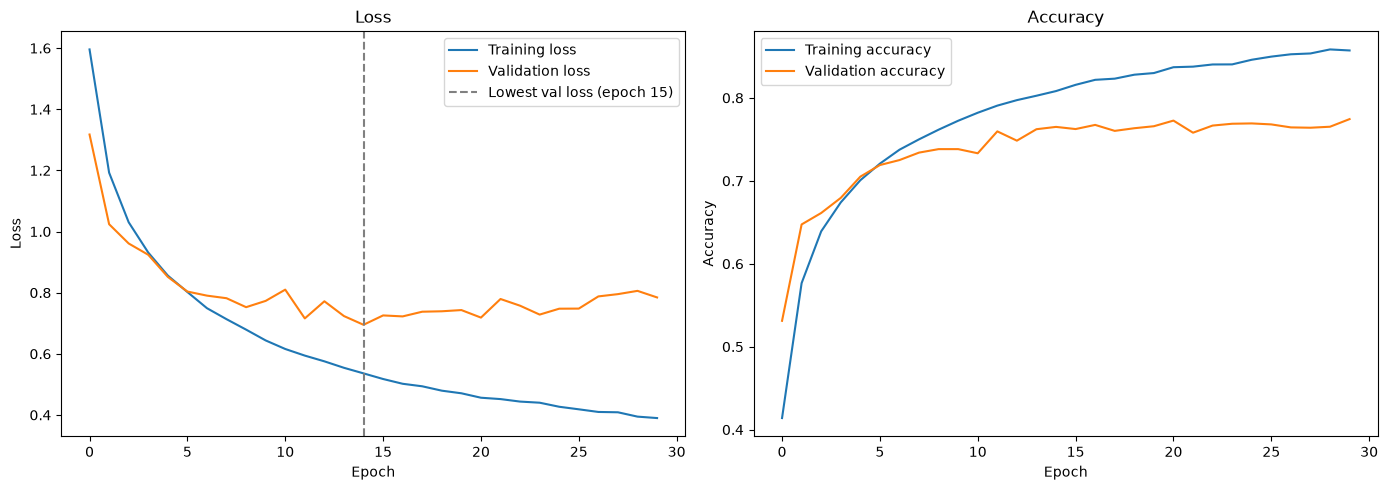

In [8]:
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

hist = pd.DataFrame(history_baseline.history)
best_epoch = hist["val_loss"].idxmin() + 1

print("Epoch with the lowest validation loss:", best_epoch)
print("Lowest validation loss:", round(hist["val_loss"].min(), 4))
print("Last epoch -> train acc:", round(hist["accuracy"].iloc[-1], 4),
      "| val acc:", round(hist["val_accuracy"].iloc[-1], 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist["loss"], label="Training loss")
axes[0].plot(hist["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch - 1, color="gray", linestyle="--", label=f"Lowest val loss (epoch {best_epoch})")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(hist["accuracy"], label="Training accuracy")
axes[1].plot(hist["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves_cnn_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Accuracy and Error rate analysis
test_loss, test_accuracy = model_baseline.evaluate(X_test_scaled, y_test_cat, verbose=1)

print (f'test loss: {test_loss:.4f}')
print (f'test accuracy: {test_accuracy:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7609 - loss: 0.8153
test loss: 0.8153
test accuracy: 0.7609


<div style="
background:linear-gradient(135deg,#08131f,#0d1b2a,#132238);
border:1px solid #00d4ff;
border-left: 8px solid #00E5FF;
border-radius:18px;
padding:25px;
box-shadow:0 0 25px rgba(0,212,255,.25);
color:white;
font-family:Segoe UI;
">

<h2 style="color:#00E5FF;">🤖 Hyperparameters CNN</h2>
<hr style="border:1px solid #8A2BE2;opacity:.4;">

In [10]:
def build_cnn(filters, convs_per_block, dropout, learning_rate, dense_units=(128,)):
    """Builds a CNN. dropout=0.0 means no Dropout layers at all."""
    model = Sequential()
    model.add(tf.keras.Input(shape=(32, 32, 3)))

    for number_of_filters in filters:
        for _ in range(convs_per_block):
            model.add(Conv2D(number_of_filters, (3, 3), padding="same", activation="relu"))
        model.add(MaxPooling2D((2, 2)))
        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Flatten())
    for units in dense_units:                       # one Dense layer for each number in the list
        model.add(Dense(units, activation="relu"))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [11]:
EPOCHS = 30

def train_and_score(
    name, 
    filters, 
    convs_per_block, 
    dropout, 
    learning_rate, 
    batch_size, 
    use_early_stopping=False, 
    patience=5, 
    lr_factor=None):
    
    """Trains one model and returns one row of results (a dictionary)."""
    tf.keras.backend.clear_session()               # free the memory of the previous model
    tf.keras.utils.set_random_seed(RANDOM_STATE)   # same starting point for every model

    model = build_cnn(filters, convs_per_block, dropout, learning_rate)

    callbacks = []
    if use_early_stopping:
        callbacks.append(EarlyStopping(monitor="val_accuracy", patience=patience, restore_best_weights=True))

    start = time.time()
    history = model.fit(
        X_train_scaled, y_train_cat,
        validation_data=(X_val_scaled, y_val_cat),
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0,
    )
    seconds = round(time.time() - start)

    val_acc = history.history["val_accuracy"]      # one number per epoch
    train_acc = history.history["accuracy"]
    best_val_acc = max(val_acc)
    best_epoch = val_acc.index(best_val_acc) + 1   # +1 because epochs are counted from 1

    print(f"{name}: best validation accuracy {best_val_acc:.4f} (epoch {best_epoch}), {seconds} s")

    return {
        "model": name,
        "batch_size": batch_size,
        "learning_rate": learning_rate,
        "dropout": dropout,
        "parameters": model.count_params(),
        "best_val_acc": round(best_val_acc, 4),
        "best_epoch": best_epoch,
        "epochs_run": len(val_acc),
        "final_train_acc": round(train_acc[-1], 4),
        "final_val_acc": round(val_acc[-1], 4),
        "seconds": seconds,
    }

In [12]:
architectures = [
    # name,          filters,          convs per block
    
    ('baseline',     [32, 64, 128],        1),
    ("wider",        [64, 64, 128, 256],   1),
    ("deeper",       [32, 64, 128, 256],   2),
    ("wider_deeper", [64, 128, 128, 256],  2),
]

results = []
for name, filters, convs in architectures:
    row = train_and_score(name, filters, convs, 0.25, 0.001, 64)   # dropout: 0.25, lr: 0.001, batch: 64
    results.append(row)

results_df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)
results_df.to_csv("../reports/tuning_1_architecture.csv", index=False)
results_df

I0000 00:00:1795803999.363012   28910 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_100948__.47
I0000 00:00:1795804006.082718   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_100948__.47


baseline: best validation accuracy 0.7866 (epoch 29), 95 s


I0000 00:00:1795804095.218430   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_198745__.57
I0000 00:00:1795804103.996766   28909 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_198745__.57


wider: best validation accuracy 0.7994 (epoch 30), 128 s


I0000 00:00:1795804224.128425   28910 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_297819__.61
I0000 00:00:1795804235.254793   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_297819__.61


deeper: best validation accuracy 0.8074 (epoch 27), 231 s


I0000 00:00:1795804455.685618   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_397005__.61
I0000 00:00:1795804470.549585   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_397005__.61


wider_deeper: best validation accuracy 0.7976 (epoch 29), 422 s


,model,batch_size,learning_rate,dropout,parameters,best_val_acc,best_epoch,epochs_run,final_train_acc,final_val_acc,seconds
2,deeper,64,0.001,0.25,1304746,0.8074,27,30,0.8240,0.8046,231
1,wider,64,0.001,0.25,540234,0.7994,30,30,0.8087,0.7994,128
3,wider_deeper,64,0.001,0.25,1573066,0.7976,29,30,0.8190,0.7956,422
0,baseline,64,0.001,0.25,356810,0.7866,29,30,0.8015,0.7820,95


In [18]:
# Find the best batch size and learning rate

# Stage 2
best_filters = [32, 64, 128, 256]   # winner of stage 1
best_convs = 2                  # winner of stage 1
EPOCHS = 50

results = []
for batch_size in [64, 128]:
    for learning_rate in [0.001, 0.005, 0.0001, 0.0005]:
        name = f"batch_{batch_size}_lr_{learning_rate}"
        row = train_and_score(name, best_filters, best_convs, 0.25, learning_rate, batch_size, use_early_stopping=True)
        results.append(row)

results_df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)
results_df.to_csv("../reports/tuning_2_batch_and_lr.csv", index=False)
results_df

I0000 00:00:1795805851.463429   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_783325__.61
I0000 00:00:1795805870.815929   28909 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_783325__.61


batch_64_lr_0.001: best validation accuracy 0.8008 (epoch 25), 459 s


I0000 00:00:1795806309.979194   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_883330__.61
I0000 00:00:1795806329.328437   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_883330__.61


batch_64_lr_0.005: best validation accuracy 0.1000 (epoch 1), 103 s


I0000 00:00:1795806413.782785   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_906879__.61
I0000 00:00:1795806433.336645   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_906879__.61


batch_64_lr_0.0001: best validation accuracy 0.8214 (epoch 38), 601 s


... (7 outputs left out)

batch_128_lr_0.0001: best validation accuracy 0.7894 (epoch 45), 434 s


I0000 00:00:1795808403.337492   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1312880__.61
I0000 00:00:1795808413.512177   28910 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1312880__.61


batch_128_lr_0.0005: best validation accuracy 0.8136 (epoch 21), 179 s


,model,batch_size,learning_rate,dropout,parameters,best_val_acc,best_epoch,epochs_run,final_train_acc,final_val_acc,seconds
3,batch_64_lr_0.0005,64,0.0005,0.25,1304746,0.8256,21,26,0.8987,0.8198,298
4,batch_128_lr_0.001,128,0.0010,0.25,1304746,0.8224,40,45,0.8917,0.8092,563
2,batch_64_lr_0.0001,64,0.0001,0.25,1304746,0.8214,38,43,0.8884,0.8076,601
7,batch_128_lr_0.0005,128,0.0005,0.25,1304746,0.8136,21,26,0.9016,0.8080,179
0,batch_64_lr_0.001,64,0.0010,0.25,1304746,0.8008,25,30,0.8104,0.7736,459
6,batch_128_lr_0.0001,128,0.0001,0.25,1304746,0.7894,45,50,0.8558,0.7840,434
1,batch_64_lr_0.005,64,0.0050,0.25,1304746,0.1000,1,6,0.1030,0.1000,103
5,batch_128_lr_0.005,128,0.0050,0.25,1304746,0.1000,1,6,0.1016,0.1000,90


In [19]:
# Find the best Dropout

# Stage 3
best_learning_rate = 0.0005   # <- winner of stage 2
best_batch_size = 64

results = []
for dropout in [0.2, 0.3, 0.4]:
    row = train_and_score(f"dropout_{dropout}", best_filters, best_convs, dropout, best_learning_rate, best_batch_size, use_early_stopping=True)
    results.append(row)

results_df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)
results_df.to_csv("../reports/tuning_3_dropout.csv", index=False)
results_df

I0000 00:00:1795808725.181090   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1359585__.61
I0000 00:00:1795808734.267805   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1359585__.61


dropout_0.2: best validation accuracy 0.8192 (epoch 17), 133 s


I0000 00:00:1795808858.009488   28909 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1434158__.61
I0000 00:00:1795808867.021149   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1434158__.61


dropout_0.3: best validation accuracy 0.8286 (epoch 31), 219 s


I0000 00:00:1795809078.425051   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1553317__.61
I0000 00:00:1795809087.274731   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1553317__.61


dropout_0.4: best validation accuracy 0.8212 (epoch 22), 161 s


,model,batch_size,learning_rate,dropout,parameters,best_val_acc,best_epoch,epochs_run,final_train_acc,final_val_acc,seconds
1,dropout_0.3,64,0.0005,0.3,1304746,0.8286,31,36,0.9004,0.8206,219
2,dropout_0.4,64,0.0005,0.4,1304746,0.8212,22,27,0.8311,0.8112,161
0,dropout_0.2,64,0.0005,0.2,1304746,0.8192,17,22,0.9126,0.8090,133


In [22]:
# add the Early Stopping

# Stage 5
best_dropout = 0.3  # <- winner of stage 4
EPOCHS = 100          # more room, because early stopping will cut the training when needed

results = []
for patience in [3, 6, 8]:
    row = train_and_score(f"patience_{patience}", best_filters, best_convs, best_dropout, best_learning_rate, best_batch_size, use_early_stopping=True, patience=patience)
    results.append(row)
    
results_df = pd.DataFrame(results).sort_values("best_val_acc", ascending=False)
results_df.to_csv("../reports/tuning_4_callbacks.csv", index=False)
results_df

I0000 00:00:1795810486.267208   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2062894__.61
I0000 00:00:1795810495.724531   28913 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2062894__.61


patience_3: best validation accuracy 0.8214 (epoch 17), 127 s


I0000 00:00:1795810612.596090   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2131269__.61
I0000 00:00:1795810621.883479   28912 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2131269__.61


patience_6: best validation accuracy 0.8416 (epoch 58), 376 s


I0000 00:00:1795810989.744469   28911 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2339040__.61
I0000 00:00:1795810998.629640   28909 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_2339040__.61


patience_8: best validation accuracy 0.8376 (epoch 41), 287 s


,model,batch_size,learning_rate,dropout,parameters,best_val_acc,best_epoch,epochs_run,final_train_acc,final_val_acc,seconds
1,patience_6,64,0.0005,0.3,1304746,0.8416,58,64,0.9286,0.8368,376
2,patience_8,64,0.0005,0.3,1304746,0.8376,41,49,0.9119,0.8340,287
0,patience_3,64,0.0005,0.3,1304746,0.8214,17,20,0.8506,0.8204,127
